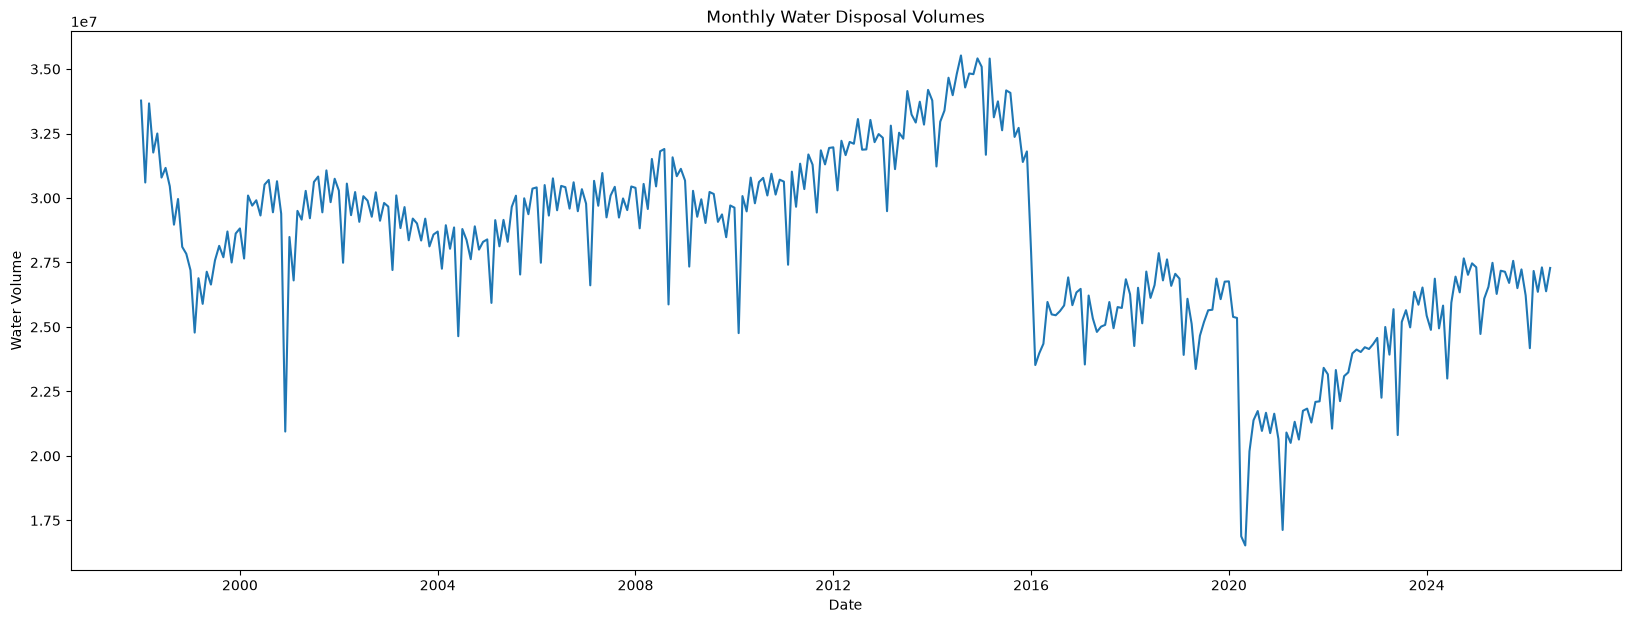

In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")
monthly_water_vols = df[['Month/ Year', 'Total Disposed Water Volume']].copy()
# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]
# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']
# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]


# Data is clean from the SARIMA script, I must figure out how to plot this data.

fig, ax = plt.subplots(figsize=(20,7))

ax.plot(monthly_water_vols['Date'], monthly_water_vols['Water Volume'], label = 'Water Disposal Volume')
ax.set_title('Monthly Water Disposal Volumes')
ax.set_xlabel('Date')
ax.set_ylabel('Water Volume')
plt.show()
                    




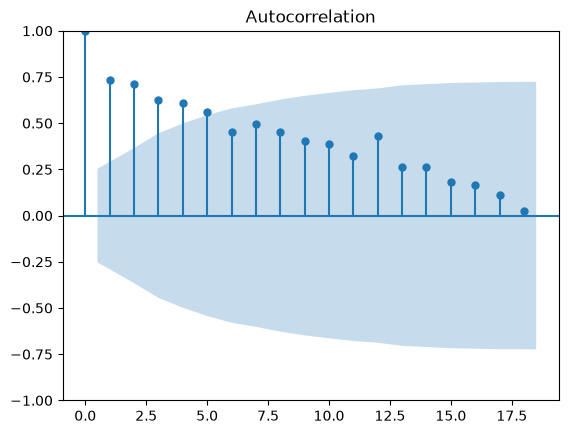

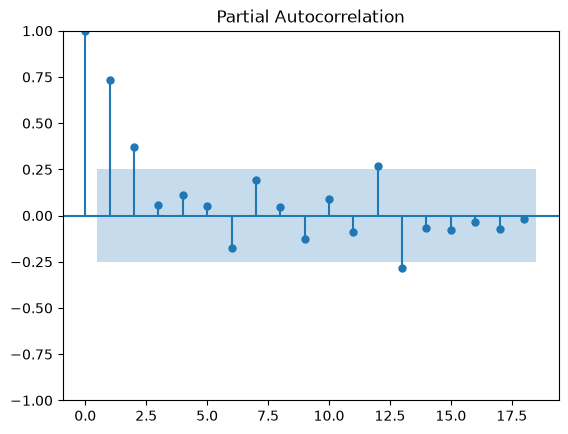

('Mean Error (ME): ', np.float64(-673080.9915384421))
('Root Mean Squared Error (RMSE): ', 873523.8057270898)
('Mean Absolute Error (MAE): ', np.float64(754178.4134234621))
('Mean Percent Error (MPE): ', np.float64(-2.6054496176635777))
('Mean Absolute Percent Error (MAPE): ', np.float64(2.9039308478789794))
('R squared : ', np.float64(0.2559770614612322))
('Adjusted R squared: ', np.float64(-0.11603440780815166))





In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from regression_utils import *

df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")
pd.set_option('display.max_rows', 90)

monthly_water_vols = df[['Month/ Year', 'Total Disposed Water Volume']].copy()
# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]
# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']
# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# change Date to a Period data type
#monthly_water_vols['Date'] = monthly_water_vols['Date'].dt.to_period(freq='M')


# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]

#Changing the dataframe to represent the last 5 years.
mask = (monthly_water_vols['Date'] >= '2021-01') & (monthly_water_vols['Date'] <= '2026-07')
subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '2021-01') & (subset['Date'] <= '2025-12')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2026-01') & (subset['Date'] <= '2026-07')
validation = subset[validation_mask]

training_data = np.asarray(training['Water Volume'])

plot_acf(training_data)
plot_pacf(training_data)
plt.show()

regressionSummary(validation['Water Volume'], forecast, monthly_water_vols)

In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import matplotlib.dates as mdates




df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")
#pd.set_option('display.max_rows', 90)

monthly_water_vols = df[['Month/ Year', 'Total Disposed Water Volume']].copy()
# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]
# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']
# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]


# This function checks if the data has 'stationarity'
#Also checks and prints the p_value
# Uses the augmented Dickey-Fuller test
def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag = 'AIC')
    p_value = result[1]
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Stationary' if p_value < 0.05 else 'Non-stationary')


#check_stationarity(monthly_water_vols['Water Volume'])

#Changing the dataframe to represent the last 5 years.
mask = (monthly_water_vols['Date'] >= '2021-01-01') & (monthly_water_vols['Date'] <= '2026-07-01')
subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '2021-01-01') & (subset['Date'] <= '2025-12-01')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2026-01-01') & (subset['Date'] <= '2026-07-01')
validation = subset[validation_mask]

#training_data = np.asarray(training['Water Volume'])

#SARIMA MODEL Parameters
for p in range(1, 4):
    for d in range(1, 4):
        for q in range(1, 4):
            for P in range(1, 4):
                for D in range(1, 4):
                    for Q in range(1, 4):
                        # p, d, q = 1, 2, 1
                        # P, D, Q, s = 1, 1, 1, 12
                        print(f"p/P = {p}, d/D = {d} q/Q = {q}")
                        
                        model = SARIMAX(training['Water Volume'], order=(p, d, q), seasonal_order=(p, d, q, 12))
                        results = model.fit()
                    
                        forecast_periods = 7
                        forecast = results.forecast(forecast_periods)
    # fig, ax = plt.subplots()

    # ax.plot(training['Date'], training['Water Volume'], label='Observed')
    # ax.plot(validation['Date'], forecast, label='Forecast', color='red')
    # ax.set_title("Disposal Volume Forecast")
    # ax.set_xlabel("Date")
    # ax.set_ylabel("Volume")
    # ax.grid()
    # fig.legend()
    # fig.show()
    
    # fig, ax = plt.subplots()
    # ax.plot(training['Date'], training['Water Volume'], label='Observed')
    # ax.plot(validation['Date'], validation['Water Volume'], label='Actual', color='cyan')
    # ax.set_title("Disposal Volume Actual")
    # ax.set_xlabel("Date")
    # ax.set_ylabel("Volume")
    # ax.grid()
    # fig.legend()
    # fig.show() 

                        adj_Rsquared = adj_R_squared(validation['Water Volume'], forecast, monthly_water_vols)
                        # if adj_Rsquared > 0.40:
                        print(f"Adjusted R squared: {adj_Rsquared}, p: {p}, d: {d}, q: {q}, P:{P}, D: {D}, Q:{Q}\n")
                        #regressionSummary(validation['Water Volume'], forecast, monthly_water_vols)

